In [123]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import vf_concave

In [163]:
Y=[(0,1),(0,1)]
X=[(0,1)]


def gcp(x,y):
    return x@y

In [164]:
x0=[1,1]
y0=[0,1]
vf_concave(x0,y0,gcp,Y)

(np.float64(2.0), array([1., 1.]))

In [174]:
n=2
k=20
ps=[np.random.rand(n) for i in range(k)]
A=cp.Variable((n,n), symmetric=True)
b=cp.Variable(n)
constraints = [A >> 0]
constraints=[cp.norm(A,"inf")<=10]
for i in range(k):
    constraints+=[cp.norm(A@ps[i]+b,2)<=1]
prob = cp.Problem(cp.Minimize(-cp.log_det(A)), constraints)
prob.solve()

np.float64(-1.1986742642925003)

0.2598232847844535
0.11820633638910581
0.5884824721863539
0.6423000114695547
0.9999999999911462
0.9999999999483861
0.6953186146314262
0.5851611071616459
0.7667412916037193
0.9999999999353323
0.8425679652696301
0.6419191018314889
0.8148610940935043
0.9999999999641592
0.5768972165613684
0.5160885335196117
0.6449054028645881
0.13416537742121795
0.9102760920502152
0.6197648281688517


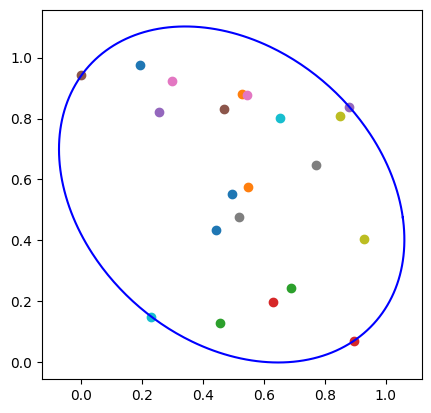

In [175]:

fig, ax = plt.subplots()
ax.set(aspect=1)
for i in range(k):
    plt.scatter(ps[i][0],ps[i][1])
    print(np.linalg.norm(A.value@ps[i]+b.value,2))

def ellipse(A,b,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    eigval,eigvec=np.linalg.eig(A)
    D=np.diag(eigval)
    c=-np.linalg.inv(A)@b
    plt.scatter(c[0],c[1])
    a=eigval[0]
    b=eigval[1]
    rot=eigvec.T
    for i in range(N):
        x[i],y[i]=np.linalg.inv(A)@(np.array([np.cos(t[i]),np.sin(t[i])]))+c
    return x,y


N = 400

xnew,ynew=ellipse(A.value,b.value,N)
plt.plot(xnew, ynew, "b")

In [102]:
eigvec@D@eigvec.T

array([[10.00094532, -0.09722639],
       [-0.09722639,  9.99905455]])